In [1]:
from google.colab import files
uploaded = files.upload()

Saving customer_base.csv to customer_base.csv


In [4]:
import pandas as pd

df = pd.read_csv('customer_base.csv')
df.head()

,customer_id,country,order_count,total_items,total_revenue,first_invoice_date,last_invoice_date
0,12346,United Kingdom,1,74215,77183.60,2011-01-18 10:01:00+08,2011-01-18 10:01:00+08
1,12347,Iceland,7,2458,4310.00,2010-12-07 14:57:00+08,2011-12-07 15:52:00+08
2,12348,Finland,4,2332,1437.24,2010-12-16 19:09:00+08,2011-09-25 13:13:00+08
3,12349,Italy,1,630,1457.55,2011-11-21 09:51:00+08,2011-11-21 09:51:00+08
4,12350,Norway,1,196,294.40,2011-02-02 16:01:00+08,2011-02-02 16:01:00+08


In [6]:
df['r_score'] = pd.qcut(df['order_count'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)

In [8]:
# Recency = days between each customer's last purchase and the latest date in the whole dataset
df['last_invoice_date'] = pd.to_datetime(df['last_invoice_date'])
snapshot_date = df['last_invoice_date'].max() + pd.Timedelta(days=1)
df['recency_days'] = (snapshot_date - df['last_invoice_date']).dt.days

df['r_score'] = pd.qcut(df['recency_days'], 5, labels=[5, 4, 3, 2, 1]).astype(int)
df['f_score'] = pd.qcut(df['order_count'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
df['m_score'] = pd.qcut(df['total_revenue'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)

df['rfm_score'] = df['r_score'].astype(str) + df['f_score'].astype(str) + df['m_score'].astype(str)
df[['customer_id', 'recency_days', 'r_score', 'order_count', 'f_score', 'total_revenue', 'm_score', 'rfm_score']].head(10)

,customer_id,recency_days,r_score,order_count,f_score,total_revenue,m_score,rfm_score
0,12346,326,1,1,1,77183.60,5,115
1,12347,2,5,7,5,4310.00,5,555
2,12348,75,2,4,4,1437.24,4,244
3,12349,19,4,1,1,1457.55,4,414
4,12350,310,1,1,1,294.40,2,112
5,12352,36,3,7,5,1385.74,4,354
6,12353,204,1,1,1,89.00,1,111
7,12354,232,1,1,1,1079.40,4,114
8,12355,214,1,1,1,459.40,2,112
9,12356,23,4,3,3,2487.43,5,435


In [9]:
def segment(row):
    r, f, m = row['r_score'], row['f_score'], row['m_score']
    if r >= 4 and f >= 4 and m >= 4:
        return 'Champions'
    elif r >= 3 and f >= 3:
        return 'Loyal'
    elif r >= 4 and f <= 2:
        return 'New Customers'
    elif r >= 3 and f <= 2:
        return 'Potential Loyalists'
    elif r <= 2 and f >= 3:
        return 'At Risk'
    else:
        return 'Hibernating'

df['segment'] = df.apply(segment, axis=1)
df['segment'].value_counts()

,count
segment,
Hibernating,1068
Loyal,1005
Champions,958
At Risk,637
Potential Loyalists,347
New Customers,319


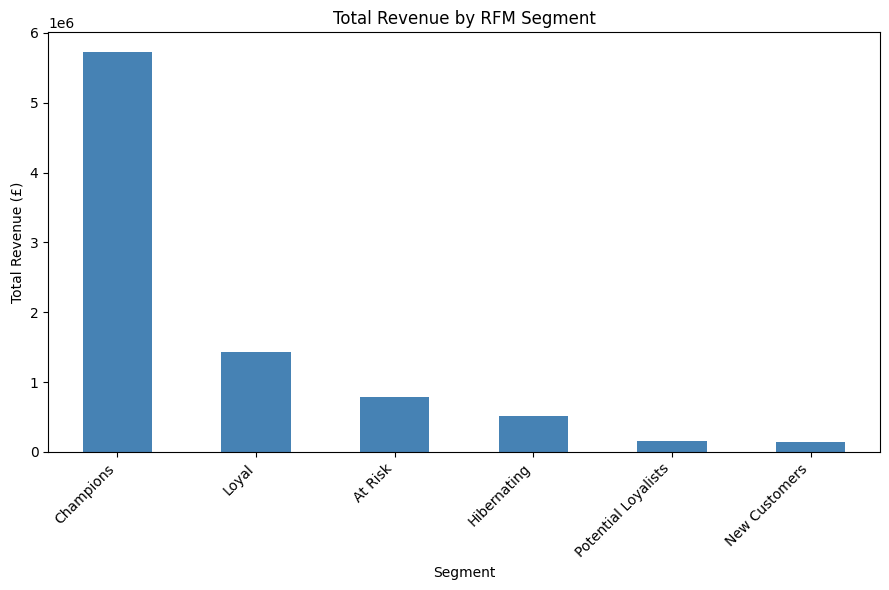

In [10]:
import matplotlib.pyplot as plt

segment_revenue = df.groupby('segment')['total_revenue'].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 6))
segment_revenue.plot(kind='bar', color='steelblue')
plt.title('Total Revenue by RFM Segment')
plt.xlabel('Segment')
plt.ylabel('Total Revenue (£)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('segment_revenue.png', dpi=150)
plt.show()

In [12]:
df.to_csv('rfm_segments.csv', index=False)
files.download('rfm_segments.csv')
files.download('segment_revenue.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>